# Day 6: Feature Engineering

## Feature Engineering Overview

Feature Engineering transforms raw columns into useful inputs for ML models.

Benefits:
- Better model accuracy
- Less noise in data
- Clearer patterns

### Feature Types

- Numerical: age, salary
- Categorical: gender, city
- Text: reviews
- Date-Time: timestamps

In [1]:
import pandas as pd
import numpy as np

data = {
    "Name": ["Alice", "Bob", "Charlie"],
    "Age": [25, 30, 35],
    "Gender": ["Female", "Male", "Male"],
    "Salary": [50000, 60000, 70000],
    "Joining_Date": ["2022-01-01", "2021-06-15", "2020-03-20"]
}
df = pd.DataFrame(data)
df

,Name,Age,Gender,Salary,Joining_Date
0,Alice,25,Female,50000,2022-01-01
1,Bob,30,Male,60000,2021-06-15
2,Charlie,35,Male,70000,2020-03-20


In [2]:
df.dtypes

,0
Name,object
Age,int64
Gender,object
Salary,int64
Joining_Date,object


## Working with Numerical Features

In [3]:
data_num = {
    "Age": [18, 29, 90, 40, 60],
    "Salary": [20000, 30000, 500000, 80000, 150000]
}
dfn = pd.DataFrame(data_num)
dfn

,Age,Salary
0,18,20000
1,29,30000
2,90,500000
3,40,80000
4,60,150000


### Standardization

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = dfn.copy()
df_scaled[["Age", "Salary"]] = scaler.fit_transform(dfn[["Age", "Salary"]])
df_scaled

,Age,Salary
0,-1.156513,-0.763804
1,-0.723804,-0.707642
2,1.675763,1.931975
3,-0.291095,-0.426832
4,0.495648,-0.033697


### Min-Max Scaling

In [5]:
from sklearn.preprocessing import MinMaxScaler

scaler_mm = MinMaxScaler()
df_normalized = dfn.copy()
df_normalized[["Age", "Salary"]] = scaler_mm.fit_transform(dfn[["Age", "Salary"]])
df_normalized

,Age,Salary
0,0.000000,0.000000
1,0.152778,0.020833
2,1.000000,1.000000
3,0.305556,0.125000
4,0.583333,0.270833


### Log Transformation

In [6]:
df_log = dfn.copy()
df_log["Salary_Log"] = np.log(df_log["Salary"])
df_log

,Age,Salary,Salary_Log
0,18,20000,9.903488
1,29,30000,10.308953
2,90,500000,13.122363
3,40,80000,11.289782
4,60,150000,11.918391


### Binning

In [7]:
bins = [0, 20, 40, 100]
labels = ["Young", "Adult", "Senior"]

df_bin = dfn.copy()
df_bin["Age_Group"] = pd.cut(df_bin["Age"], bins=bins, labels=labels)
df_bin

,Age,Salary,Age_Group
0,18,20000,Young
1,29,30000,Adult
2,90,500000,Senior
3,40,80000,Adult
4,60,150000,Senior


## Working with Categorical Features

In [8]:
data_cat = {
    "Name": ["A", "B", "C", "D", "E", "F"],
    "Gender": ["Male", "Female", "Female", "Male", "Male", "Female"],
    "City": ["Mumbai", "Delhi", "Mumbai", "Pune", "Delhi", "Delhi"],
    "Performance": ["Low", "Medium", "High", "Medium", "Low", "High"]
}
dfc = pd.DataFrame(data_cat)
dfc

,Name,Gender,City,Performance
0,A,Male,Mumbai,Low
1,B,Female,Delhi,Medium
2,C,Female,Mumbai,High
3,D,Male,Pune,Medium
4,E,Male,Delhi,Low
5,F,Female,Delhi,High


### Label Encoding

In [9]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
dfc_le = dfc.copy()
dfc_le["Gender_Label"] = le.fit_transform(dfc_le["Gender"])
dfc_le["City_Label"] = le.fit_transform(dfc_le["City"])
dfc_le

,Name,Gender,City,Performance,Gender_Label,City_Label
0,A,Male,Mumbai,Low,1,1
1,B,Female,Delhi,Medium,0,0
2,C,Female,Mumbai,High,0,1
3,D,Male,Pune,Medium,1,2
4,E,Male,Delhi,Low,1,0
5,F,Female,Delhi,High,0,0


### Ordinal Encoding

In [10]:
order = {"Low": 3, "Medium": 2, "High": 1}

dfc_ord = dfc.copy()
dfc_ord["Performance_Ordinal"] = dfc_ord["Performance"].map(order)
dfc_ord

,Name,Gender,City,Performance,Performance_Ordinal
0,A,Male,Mumbai,Low,3
1,B,Female,Delhi,Medium,2
2,C,Female,Mumbai,High,1
3,D,Male,Pune,Medium,2
4,E,Male,Delhi,Low,3
5,F,Female,Delhi,High,1


### Frequency Encoding

In [11]:
freq = dfc["City"].value_counts()

dfc_freq = dfc.copy()
dfc_freq["City_Freq"] = dfc_freq["City"].map(freq)
dfc_freq

,Name,Gender,City,Performance,City_Freq
0,A,Male,Mumbai,Low,2
1,B,Female,Delhi,Medium,3
2,C,Female,Mumbai,High,2
3,D,Male,Pune,Medium,1
4,E,Male,Delhi,Low,3
5,F,Female,Delhi,High,3


### Target Encoding

In [12]:
dfc_t = dfc.copy()
dfc_t["Target"] = [0, 1, 1, 0, 1, 2]

target_mean = dfc_t.groupby("City")["Target"].mean()
dfc_t["City_Target_Encoded"] = dfc_t["City"].map(target_mean)
dfc_t

,Name,Gender,City,Performance,Target,City_Target_Encoded
0,A,Male,Mumbai,Low,0,0.500000
1,B,Female,Delhi,Medium,1,1.333333
2,C,Female,Mumbai,High,1,0.500000
3,D,Male,Pune,Medium,0,0.000000
4,E,Male,Delhi,Low,1,1.333333
5,F,Female,Delhi,High,2,1.333333


### One Hot Encoding

In [13]:
pd.get_dummies(dfc, columns=["City"])

,Name,Gender,Performance,City_Delhi,City_Mumbai,City_Pune
0,A,Male,Low,False,True,False
1,B,Female,Medium,True,False,False
2,C,Female,High,False,True,False
3,D,Male,Medium,False,False,True
4,E,Male,Low,True,False,False
5,F,Female,High,True,False,False


## Date and Time Features

In [14]:
data_dt = {
    "Name": ["A", "B", "C"],
    "Joining_Date": ["2022-01-15", "2021-06-20", "2020-12-05"]
}
dfd = pd.DataFrame(data_dt)
dfd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Name          3 non-null      object
 1   Joining_Date  3 non-null      object
dtypes: object(2)
memory usage: 180.0+ bytes


In [15]:
dfd["Joining_Date"] = pd.to_datetime(dfd["Joining_Date"])
dfd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Name          3 non-null      object        
 1   Joining_Date  3 non-null      datetime64[ns]
dtypes: datetime64[ns](1), object(1)
memory usage: 180.0+ bytes


### Extracting Date Parts

In [16]:
dfd["Year"] = dfd["Joining_Date"].dt.year
dfd["Month"] = dfd["Joining_Date"].dt.month
dfd["Day"] = dfd["Joining_Date"].dt.day
dfd["Weekday"] = dfd["Joining_Date"].dt.day_name()
dfd

,Name,Joining_Date,Year,Month,Day,Weekday
0,A,2022-01-15,2022,1,15,Saturday
1,B,2021-06-20,2021,6,20,Sunday
2,C,2020-12-05,2020,12,5,Saturday


### Extracting Time Parts

In [17]:
dfd["Full_DateTime"] = pd.to_datetime([
    "2022-01-15 10:30:00",
    "2021-06-20 14:45:00",
    "2020-12-05 08:15:00"
])

dfd["Hour"] = dfd["Full_DateTime"].dt.hour
dfd["Minute"] = dfd["Full_DateTime"].dt.minute
dfd

,Name,Joining_Date,Year,Month,Day,Weekday,Full_DateTime,Hour,Minute
0,A,2022-01-15,2022,1,15,Saturday,2022-01-15 10:30:00,10,30
1,B,2021-06-20,2021,6,20,Sunday,2021-06-20 14:45:00,14,45
2,C,2020-12-05,2020,12,5,Saturday,2020-12-05 08:15:00,8,15


### Cyclical Encoding

In [18]:
dfd["Month_sin"] = np.sin(2 * np.pi * dfd["Month"] / 12)
dfd["Month_cos"] = np.cos(2 * np.pi * dfd["Month"] / 12)
dfd

,Name,Joining_Date,Year,Month,Day,Weekday,Full_DateTime,Hour,Minute,Month_sin,Month_cos
0,A,2022-01-15,2022,1,15,Saturday,2022-01-15 10:30:00,10,30,5.000000e-01,0.866025
1,B,2021-06-20,2021,6,20,Sunday,2021-06-20 14:45:00,14,45,1.224647e-16,-1.000000
2,C,2020-12-05,2020,12,5,Saturday,2020-12-05 08:15:00,8,15,-2.449294e-16,1.000000


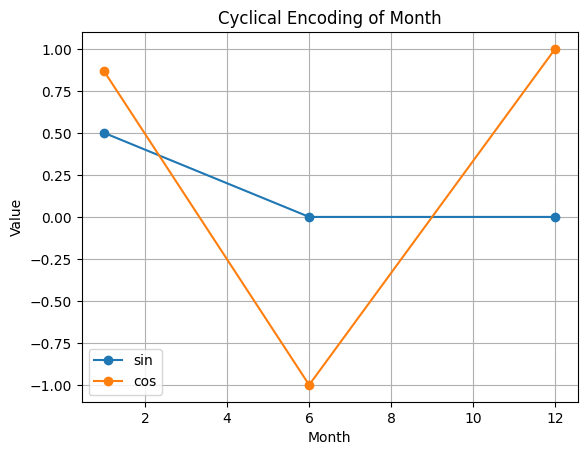

In [19]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(dfd["Month"], dfd["Month_sin"], marker="o", label="sin")
plt.plot(dfd["Month"], dfd["Month_cos"], marker="o", label="cos")
plt.xlabel("Month")
plt.ylabel("Value")
plt.title("Cyclical Encoding of Month")
plt.legend()
plt.grid()
plt.show()

## Creating New Features

In [20]:
data_fc = {
    "Name": ["A", "B", "C"],
    "Price": [100, 200, 150],
    "Quantity": [2, 3, 5],
    "First_Name": ["John", "Jane", "Sam"],
    "Last_Name": ["Doe", "Smith", "Brown"],
    "Email": ["john@gmail.com", "jane@yahoo.com", "sam@outlook.com"]
}
df = pd.DataFrame(data_fc)
df

,Name,Price,Quantity,First_Name,Last_Name,Email
0,A,100,2,John,Doe,john@gmail.com
1,B,200,3,Jane,Smith,jane@yahoo.com
2,C,150,5,Sam,Brown,sam@outlook.com


### Arithmetic Transformations

In [21]:
df["Total_Price"] = df["Price"] * df["Quantity"]
df

,Name,Price,Quantity,First_Name,Last_Name,Email,Total_Price
0,A,100,2,John,Doe,john@gmail.com,200
1,B,200,3,Jane,Smith,jane@yahoo.com,600
2,C,150,5,Sam,Brown,sam@outlook.com,750


### Combining Columns

In [22]:
df["Full_Name"] = df["First_Name"] + " " + df["Last_Name"]
df

,Name,Price,Quantity,First_Name,Last_Name,Email,Total_Price,Full_Name
0,A,100,2,John,Doe,john@gmail.com,200,John Doe
1,B,200,3,Jane,Smith,jane@yahoo.com,600,Jane Smith
2,C,150,5,Sam,Brown,sam@outlook.com,750,Sam Brown


### Information Extraction

In [23]:
df["Email_Domain"] = df["Email"].apply(lambda x: x.split("@")[1])
df

,Name,Price,Quantity,First_Name,Last_Name,Email,Total_Price,Full_Name,Email_Domain
0,A,100,2,John,Doe,john@gmail.com,200,John Doe,gmail.com
1,B,200,3,Jane,Smith,jane@yahoo.com,600,Jane Smith,yahoo.com
2,C,150,5,Sam,Brown,sam@outlook.com,750,Sam Brown,outlook.com


### Domain Knowledge Features

In [24]:
df["Weight"] = [60, 70, 80]
df["Height"] = [1.6, 1.7, 1.8]

df["BMI"] = df["Weight"] / (df["Height"] ** 2)
df

,Name,Price,Quantity,First_Name,Last_Name,Email,Total_Price,Full_Name,Email_Domain,Weight,Height,BMI
0,A,100,2,John,Doe,john@gmail.com,200,John Doe,gmail.com,60,1.6,23.437500
1,B,200,3,Jane,Smith,jane@yahoo.com,600,Jane Smith,yahoo.com,70,1.7,24.221453
2,C,150,5,Sam,Brown,sam@outlook.com,750,Sam Brown,outlook.com,80,1.8,24.691358


## Missing Value Treatment

In [25]:
data_mv = {
    "Age": [25, np.nan, 30, 35, np.nan],
    "Salary": [50000, 60000, np.nan, 80000, 90000],
    "City": ["Mumbai", "Delhi", None, "Pune", "Delhi"]
}
df = pd.DataFrame(data_mv)
df

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,NaN,60000.0,Delhi
2,30.0,NaN,None
3,35.0,80000.0,Pune
4,NaN,90000.0,Delhi


### Checking Nulls

In [26]:
df.isnull().sum()

,0
Age,2
Salary,1
City,1


### Mean Imputation

In [27]:
df2 = df.copy()
df2["Age"] = df2["Age"].fillna(df2["Age"].mean())
df2

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,30.0,60000.0,Delhi
2,30.0,NaN,None
3,35.0,80000.0,Pune
4,30.0,90000.0,Delhi


### Median Imputation

In [28]:
df2 = df.copy()
df2["Salary"] = df2["Salary"].fillna(df2["Salary"].median())
df2

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,NaN,60000.0,Delhi
2,30.0,70000.0,None
3,35.0,80000.0,Pune
4,NaN,90000.0,Delhi


### Mode Imputation

In [29]:
df2 = df.copy()
df2["City"] = df2["City"].fillna(df2["City"].mode()[0])
df2

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,NaN,60000.0,Delhi
2,30.0,NaN,Delhi
3,35.0,80000.0,Pune
4,NaN,90000.0,Delhi


### Forward Fill

In [30]:
df.ffill()

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,25.0,60000.0,Delhi
2,30.0,60000.0,Delhi
3,35.0,80000.0,Pune
4,35.0,90000.0,Delhi


### Backward Fill

In [31]:
df.bfill()

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,30.0,60000.0,Delhi
2,30.0,80000.0,Pune
3,35.0,80000.0,Pune
4,NaN,90000.0,Delhi


### Missing Indicator

In [32]:
df["Age_missing"] = df["Age"].isnull().astype(int)
df

,Age,Salary,City,Age_missing
0,25.0,50000.0,Mumbai,0
1,NaN,60000.0,Delhi,1
2,30.0,NaN,None,0
3,35.0,80000.0,Pune,0
4,NaN,90000.0,Delhi,1


## Feature Selection

In [33]:
data_fs = {
    "Age": [25, 30, 35, 40, 45],
    "Salary": [30000, 40000, 50000, 60000, 70000],
    "Experience": [1, 3, 5, 7, 9],
    "Purchased": [0, 0, 1, 1, 1]
}
df = pd.DataFrame(data_fs)
df

,Age,Salary,Experience,Purchased
0,25,30000,1,0
1,30,40000,3,0
2,35,50000,5,1
3,40,60000,7,1
4,45,70000,9,1


### Correlation Based Selection

In [34]:
df.corr()

,Age,Salary,Experience,Purchased
Age,1.000000,1.000000,1.000000,0.866025
Salary,1.000000,1.000000,1.000000,0.866025
Experience,1.000000,1.000000,1.000000,0.866025
Purchased,0.866025,0.866025,0.866025,1.000000


In [35]:
corr_with_target = df.corr()["Purchased"]
corr_with_target

,Purchased
Age,0.866025
Salary,0.866025
Experience,0.866025
Purchased,1.000000


### Dropping Low Value Columns

In [36]:
df_selected = df.drop(columns=["Age"])
df_selected

,Salary,Experience,Purchased
0,30000,1,0
1,40000,3,0
2,50000,5,1
3,60000,7,1
4,70000,9,1


## Outlier Detection and Treatment

In [37]:
data_out = {
    "Salary": [30000, 35000, 40000, 45000, 50000, 1000000, 2]
}
df = pd.DataFrame(data_out)
df

,Salary
0,30000
1,35000
2,40000
3,45000
4,50000
5,1000000
6,2


### IQR Method

In [38]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["Salary"] < lower_bound) | (df["Salary"] > upper_bound)]
outliers

,Salary
5,1000000
6,2


### Removing Outliers

In [39]:
df_no_outliers = df[(df["Salary"] >= lower_bound) & (df["Salary"] <= upper_bound)]
df_no_outliers

,Salary
0,30000
1,35000
2,40000
3,45000
4,50000


### Capping Outliers

In [40]:
df_capped = df.copy()
df_capped["Salary"] = df_capped["Salary"].clip(lower_bound, upper_bound)
df_capped

,Salary
0,30000
1,35000
2,40000
3,45000
4,50000
5,70000
6,10000


### Z Score Method

In [41]:
from scipy import stats

z_scores = stats.zscore(df["Salary"])
z_scores

array([-0.41769094, -0.40292412, -0.3881573 , -0.37339047, -0.35862365,
        2.44707244, -0.50628596])

In [42]:
df_z = df[(abs(z_scores) > 2)]
df_z

,Salary
5,1000000


## Practice Assignment

Apply feature engineering on a dataset having Age, Salary, Gender, City, Date, Purchase_Amount, Experience and Rating columns.

Solve each problem with clean code and visible output.

In [43]:
# Assignment dataset
df = pd.DataFrame({
    "Age": [22, 34, np.nan, 46, 29, 51],
    "Salary": [40000, 55000, 60000, np.nan, 48000, 75000],
    "Gender": ["M", "F", "M", "F", "M", "F"],
    "City": ["Pune", "Mumbai", "Delhi", "Pune", "Mumbai", "Delhi"],
    "Date": ["2023-01-10", "2023-02-14", "2023-03-05", "2023-04-21", "2023-05-30", "2023-06-17"],
    "Purchase_Amount": [1200, np.nan, 800, 2300, 1500, 3000],
    "Experience": [2, 9, 11, 22, 6, 26],
    "Rating": [3.5, 4.0, 4.2, 4.8, 3.9, 4.5]
})
df

,Age,Salary,Gender,City,Date,Purchase_Amount,Experience,Rating
0,22.0,40000.0,M,Pune,2023-01-10,1200.0,2,3.5
1,34.0,55000.0,F,Mumbai,2023-02-14,NaN,9,4.0
2,NaN,60000.0,M,Delhi,2023-03-05,800.0,11,4.2
3,46.0,NaN,F,Pune,2023-04-21,2300.0,22,4.8
4,29.0,48000.0,M,Mumbai,2023-05-30,1500.0,6,3.9
5,51.0,75000.0,F,Delhi,2023-06-17,3000.0,26,4.5


### Problem 1: Missing Values

In [44]:
# mean for numerical, mode for categorical
for col in ["Age", "Salary", "Purchase_Amount"]:
    df[col] = df[col].fillna(df[col].mean())
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])
df

,Age,Salary,Gender,City,Date,Purchase_Amount,Experience,Rating
0,22.0,40000.0,M,Pune,2023-01-10,1200.0,2,3.5
1,34.0,55000.0,F,Mumbai,2023-02-14,1760.0,9,4.0
2,36.4,60000.0,M,Delhi,2023-03-05,800.0,11,4.2
3,46.0,55600.0,F,Pune,2023-04-21,2300.0,22,4.8
4,29.0,48000.0,M,Mumbai,2023-05-30,1500.0,6,3.9
5,51.0,75000.0,F,Delhi,2023-06-17,3000.0,26,4.5


### Problem 2: Scaling

In [45]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

print("Before:", df["Salary"].values)
df["Salary_Std"] = StandardScaler().fit_transform(df[["Salary"]])
df["Age_MinMax"] = MinMaxScaler().fit_transform(df[["Age"]])
df

Before: [40000. 55000. 60000. 55600. 48000. 75000.]


,Age,Salary,Gender,City,Date,Purchase_Amount,Experience,Rating,Salary_Std,Age_MinMax
0,22.0,40000.0,M,Pune,2023-01-10,1200.0,2,3.5,-1.447177,0.000000
1,34.0,55000.0,F,Mumbai,2023-02-14,1760.0,9,4.0,-0.055661,0.413793
2,36.4,60000.0,M,Delhi,2023-03-05,800.0,11,4.2,0.408178,0.496552
3,46.0,55600.0,F,Pune,2023-04-21,2300.0,22,4.8,0.000000,0.827586
4,29.0,48000.0,M,Mumbai,2023-05-30,1500.0,6,3.9,-0.705035,0.241379
5,51.0,75000.0,F,Delhi,2023-06-17,3000.0,26,4.5,1.799694,1.000000


### Problem 3: Encoding

In [46]:
from sklearn.preprocessing import LabelEncoder

df["Gender_Code"] = LabelEncoder().fit_transform(df["Gender"])
df = pd.get_dummies(df, columns=["City"])
df

,Age,Salary,Gender,Date,Purchase_Amount,Experience,Rating,Salary_Std,Age_MinMax,Gender_Code,City_Delhi,City_Mumbai,City_Pune
0,22.0,40000.0,M,2023-01-10,1200.0,2,3.5,-1.447177,0.000000,1,False,False,True
1,34.0,55000.0,F,2023-02-14,1760.0,9,4.0,-0.055661,0.413793,0,False,True,False
2,36.4,60000.0,M,2023-03-05,800.0,11,4.2,0.408178,0.496552,1,True,False,False
3,46.0,55600.0,F,2023-04-21,2300.0,22,4.8,0.000000,0.827586,0,False,False,True
4,29.0,48000.0,M,2023-05-30,1500.0,6,3.9,-0.705035,0.241379,1,False,True,False
5,51.0,75000.0,F,2023-06-17,3000.0,26,4.5,1.799694,1.000000,0,True,False,False


### Problem 4: Feature Addition

In [47]:
df["Total_Spending"] = df["Salary"] + df["Purchase_Amount"]
df

,Age,Salary,Gender,Date,Purchase_Amount,Experience,Rating,Salary_Std,Age_MinMax,Gender_Code,City_Delhi,City_Mumbai,City_Pune,Total_Spending
0,22.0,40000.0,M,2023-01-10,1200.0,2,3.5,-1.447177,0.000000,1,False,False,True,41200.0
1,34.0,55000.0,F,2023-02-14,1760.0,9,4.0,-0.055661,0.413793,0,False,True,False,56760.0
2,36.4,60000.0,M,2023-03-05,800.0,11,4.2,0.408178,0.496552,1,True,False,False,60800.0
3,46.0,55600.0,F,2023-04-21,2300.0,22,4.8,0.000000,0.827586,0,False,False,True,57900.0
4,29.0,48000.0,M,2023-05-30,1500.0,6,3.9,-0.705035,0.241379,1,False,True,False,49500.0
5,51.0,75000.0,F,2023-06-17,3000.0,26,4.5,1.799694,1.000000,0,True,False,False,78000.0


### Problem 5: Date Extraction

In [48]:
df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["Weekday"] = df["Date"].dt.day_name()
df

,Age,Salary,Gender,Date,Purchase_Amount,Experience,Rating,Salary_Std,Age_MinMax,Gender_Code,City_Delhi,City_Mumbai,City_Pune,Total_Spending,Year,Month,Day,Weekday
0,22.0,40000.0,M,2023-01-10,1200.0,2,3.5,-1.447177,0.000000,1,False,False,True,41200.0,2023,1,10,Tuesday
1,34.0,55000.0,F,2023-02-14,1760.0,9,4.0,-0.055661,0.413793,0,False,True,False,56760.0,2023,2,14,Tuesday
2,36.4,60000.0,M,2023-03-05,800.0,11,4.2,0.408178,0.496552,1,True,False,False,60800.0,2023,3,5,Sunday
3,46.0,55600.0,F,2023-04-21,2300.0,22,4.8,0.000000,0.827586,0,False,False,True,57900.0,2023,4,21,Friday
4,29.0,48000.0,M,2023-05-30,1500.0,6,3.9,-0.705035,0.241379,1,False,True,False,49500.0,2023,5,30,Tuesday
5,51.0,75000.0,F,2023-06-17,3000.0,26,4.5,1.799694,1.000000,0,True,False,False,78000.0,2023,6,17,Saturday


### Problem 6: Binning

In [49]:
df["Age_Group"] = pd.cut(df["Age"], bins=[0, 25, 45, 100], labels=["Young", "Adult", "Senior"])
df

,Age,Salary,Gender,Date,Purchase_Amount,Experience,Rating,Salary_Std,Age_MinMax,Gender_Code,City_Delhi,City_Mumbai,City_Pune,Total_Spending,Year,Month,Day,Weekday,Age_Group
0,22.0,40000.0,M,2023-01-10,1200.0,2,3.5,-1.447177,0.000000,1,False,False,True,41200.0,2023,1,10,Tuesday,Young
1,34.0,55000.0,F,2023-02-14,1760.0,9,4.0,-0.055661,0.413793,0,False,True,False,56760.0,2023,2,14,Tuesday,Adult
2,36.4,60000.0,M,2023-03-05,800.0,11,4.2,0.408178,0.496552,1,True,False,False,60800.0,2023,3,5,Sunday,Adult
3,46.0,55600.0,F,2023-04-21,2300.0,22,4.8,0.000000,0.827586,0,False,False,True,57900.0,2023,4,21,Friday,Senior
4,29.0,48000.0,M,2023-05-30,1500.0,6,3.9,-0.705035,0.241379,1,False,True,False,49500.0,2023,5,30,Tuesday,Adult
5,51.0,75000.0,F,2023-06-17,3000.0,26,4.5,1.799694,1.000000,0,True,False,False,78000.0,2023,6,17,Saturday,Senior


### Problem 7: Outlier Detection

In [50]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)
IQR = Q3 - Q1
lower_b = Q1 - 1.5 * IQR
upper_b = Q3 + 1.5 * IQR

df[(df["Salary"] < lower_b) | (df["Salary"] > upper_b)]

,Age,Salary,Gender,Date,Purchase_Amount,Experience,Rating,Salary_Std,Age_MinMax,Gender_Code,City_Delhi,City_Mumbai,City_Pune,Total_Spending,Year,Month,Day,Weekday,Age_Group
5,51.0,75000.0,F,2023-06-17,3000.0,26,4.5,1.799694,1.0,0,True,False,False,78000.0,2023,6,17,Saturday,Senior


### Problem 8: Feature Interaction

In [51]:
df["Experience_Salary"] = df["Experience"] * df["Salary"]
df

,Age,Salary,Gender,Date,Purchase_Amount,Experience,Rating,Salary_Std,Age_MinMax,Gender_Code,City_Delhi,City_Mumbai,City_Pune,Total_Spending,Year,Month,Day,Weekday,Age_Group,Experience_Salary
0,22.0,40000.0,M,2023-01-10,1200.0,2,3.5,-1.447177,0.000000,1,False,False,True,41200.0,2023,1,10,Tuesday,Young,80000.0
1,34.0,55000.0,F,2023-02-14,1760.0,9,4.0,-0.055661,0.413793,0,False,True,False,56760.0,2023,2,14,Tuesday,Adult,495000.0
2,36.4,60000.0,M,2023-03-05,800.0,11,4.2,0.408178,0.496552,1,True,False,False,60800.0,2023,3,5,Sunday,Adult,660000.0
3,46.0,55600.0,F,2023-04-21,2300.0,22,4.8,0.000000,0.827586,0,False,False,True,57900.0,2023,4,21,Friday,Senior,1223200.0
4,29.0,48000.0,M,2023-05-30,1500.0,6,3.9,-0.705035,0.241379,1,False,True,False,49500.0,2023,5,30,Tuesday,Adult,288000.0
5,51.0,75000.0,F,2023-06-17,3000.0,26,4.5,1.799694,1.000000,0,True,False,False,78000.0,2023,6,17,Saturday,Senior,1950000.0


### Problem 9: Feature Selection

In [52]:
print(df.corr(numeric_only=True)["Purchase_Amount"].sort_values(ascending=False))

# drop the weakest correlated feature
df_final = df.drop(columns=["Rating"])
df_final

Purchase_Amount      1.000000
Experience_Salary    0.849356
Experience           0.832471
Age_MinMax           0.785357
Age                  0.785357
Total_Spending       0.689600
Month                0.656457
Salary               0.653637
Salary_Std           0.653637
Rating               0.641448
Day                  0.410661
City_Delhi           0.137018
City_Pune           -0.009787
City_Mumbai         -0.127231
Gender_Code         -0.821228
Year                      NaN
Name: Purchase_Amount, dtype: float64


,Age,Salary,Gender,Date,Purchase_Amount,Experience,Salary_Std,Age_MinMax,Gender_Code,City_Delhi,City_Mumbai,City_Pune,Total_Spending,Year,Month,Day,Weekday,Age_Group,Experience_Salary
0,22.0,40000.0,M,2023-01-10,1200.0,2,-1.447177,0.000000,1,False,False,True,41200.0,2023,1,10,Tuesday,Young,80000.0
1,34.0,55000.0,F,2023-02-14,1760.0,9,-0.055661,0.413793,0,False,True,False,56760.0,2023,2,14,Tuesday,Adult,495000.0
2,36.4,60000.0,M,2023-03-05,800.0,11,0.408178,0.496552,1,True,False,False,60800.0,2023,3,5,Sunday,Adult,660000.0
3,46.0,55600.0,F,2023-04-21,2300.0,22,0.000000,0.827586,0,False,False,True,57900.0,2023,4,21,Friday,Senior,1223200.0
4,29.0,48000.0,M,2023-05-30,1500.0,6,-0.705035,0.241379,1,False,True,False,49500.0,2023,5,30,Tuesday,Adult,288000.0
5,51.0,75000.0,F,2023-06-17,3000.0,26,1.799694,1.000000,0,True,False,False,78000.0,2023,6,17,Saturday,Senior,1950000.0
